# ConvNeXt V2 — transfer-learning strategies
Same data, splits, preprocessing, hyper-parameters (`configs/base.yaml`) and training loop as
`02_efficientnetv2_strategies_classification.ipynb`; only the backbone changes.

| strategy | trainable |
|---|---|
| `feature_extraction` | classifier head only |
| `partial` | head + `head.norm` + last `PARTIAL_BLOCKS` stages |
| `full` | everything |

In [1]:
import sys, json, time, copy
from pathlib import Path
import numpy as np
import pandas as pd
import yaml, timm, torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,roc_auc_score, confusion_matrix)
from tqdm.auto import tqdm

In [2]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.datasets import Preprocessor, PlantDataset

In [3]:
CFG       = yaml.safe_load((PROJECT_ROOT / "configs" / "base.yaml").read_text())
SPLIT_DIR = PROJECT_ROOT / "data" / "splits"
META      = json.loads((SPLIT_DIR / "meta.json").read_text())
CLASSES   = META["classes"]
NUM_CLASSES = len(CLASSES)

# meta.json stores an absolute path from the machine that built the splits; fall back to the repo copy.
DATA_ROOT = Path(META["data_root"])
if not DATA_ROOT.exists():
    DATA_ROOT = PROJECT_ROOT / "data" / "raw" / "plant-leaf-diseases" / "Plant_Leaf_Diseases"
assert DATA_ROOT.exists(), f"dataset not found: {DATA_ROOT}"

TIMM_NAME  = "convnextv2_tiny.fcmae_ft_in22k_in1k"
RUN_PREFIX = "convnextv2"
STRATEGIES = ["feature_extraction", "partial", "full"]
PARTIAL_BLOCKS = 2                       # last 2 of 4 stages (~same trainable share as EfficientNetV2 partial)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "| classes:", NUM_CLASSES, "| data:", DATA_ROOT)

Device: cuda | classes: 21 | data: /home/sloth/plant-diseases-classification/data/raw/plant-leaf-diseases/Plant_Leaf_Diseases


In [4]:
def set_seed(seed):
    import random
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

pcfg = timm.models.get_pretrained_cfg(TIMM_NAME)
prep = Preprocessor(CFG["img_size"], tuple(pcfg.mean), tuple(pcfg.std))

loaders = {
    name: DataLoader(PlantDataset(SPLIT_DIR / f"{name}.csv", DATA_ROOT, prep),
    batch_size=CFG["batch_size"], shuffle=(name == "train"),
    num_workers=2, pin_memory=(DEVICE == "cuda"))
    for name in ["train", "val", "test"]
}
print({k: len(v.dataset) for k, v in loaders.items()})

{'train': 28156, 'val': 6033, 'test': 6034}


In [5]:
class ConvNeXtV2Builder:
    """Builds ConvNeXt V2 and applies one transfer-learning strategy.
       feature_extraction : backbone frozen, only the new classifier (head.fc) trains
       partial            : head.fc + head.norm + last N stages train, rest frozen
       full               : everything trains
    ConvNeXt uses LayerNorm (no BatchNorm), so there are no running stats to freeze."""

    def __init__(self, timm_name, num_classes, partial_blocks=2):
        self.timm_name, self.num_classes, self.partial_blocks = timm_name, num_classes, partial_blocks

    def build(self, strategy: str) -> nn.Module:
        model = timm.create_model(self.timm_name, pretrained=True, num_classes=self.num_classes)
        self._apply_strategy(model, strategy)
        return model

    def _apply_strategy(self, model, strategy):
        for p in model.parameters():
            p.requires_grad = False

        if strategy == "full":
            for p in model.parameters():
                p.requires_grad = True
        else:
            for p in model.get_classifier().parameters():
                p.requires_grad = True
            if strategy == "partial":
                last_stages = list(model.stages.children())[-self.partial_blocks:]
                for module in [*last_stages, model.head.norm]:
                    for p in module.parameters():
                        p.requires_grad = True
            elif strategy != "feature_extraction":
                raise ValueError(f"Unknown strategy: {strategy}")

    @staticmethod
    def param_groups(model, lr_head, lr_backbone):
        head_ids = {id(p) for p in model.get_classifier().parameters()}
        head = [p for p in model.parameters() if id(p) in head_ids]
        back = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
        groups = [{"params": head, "lr": lr_head}]
        if back:
            groups.append({"params": back, "lr": lr_backbone})
        return groups

    @staticmethod
    def count_params(model):
        total = sum(p.numel() for p in model.parameters())
        trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
        return total, trainable

In [6]:
builder = ConvNeXtV2Builder(TIMM_NAME, NUM_CLASSES, PARTIAL_BLOCKS)
for s in STRATEGIES:
    total, trainable = builder.count_params(builder.build(s))
    print(f"{s:<20} trainable {trainable:>10,} / {total:,}  ({trainable/total:.1%})")

feature_extraction   trainable     16,149 / 27,882,645  (0.1%)


partial              trainable 26,641,557 / 27,882,645  (95.5%)


full                 trainable 27,882,645 / 27,882,645  (100.0%)


In [7]:
class EarlyStopping:
    """Stops when the monitored metric stops improving, keeps the best weights."""
    def __init__(self, patience=5, min_delta=0.0, mode="min", restore_best=True):
        self.patience, self.min_delta, self.mode = patience, min_delta, mode
        self.restore_best = restore_best
        self.best = float("inf") if mode == "min" else -float("inf")
        self.best_epoch, self.best_state, self.wait, self.stop = 0, None, 0, False

    def _improved(self, v):
        return v < self.best - self.min_delta if self.mode == "min" else v > self.best + self.min_delta

    def __call__(self, value, model, epoch):
        if self._improved(value):
            self.best, self.best_epoch, self.wait = value, epoch, 0
            self.best_state = copy.deepcopy(model.state_dict())
        else:
            self.wait += 1
            self.stop = self.wait >= self.patience

    def restore(self, model):
        if self.restore_best and self.best_state is not None:
            model.load_state_dict(self.best_state)


class Trainer:
    """verbose: 0 = silent | 1 = one line per epoch | 2 = + batch progress bars"""

    def __init__(self, model, loaders, cfg, param_groups, device, verbose=1):
        self.verbose = verbose
        self.model, self.loaders, self.cfg, self.device = model.to(device), loaders, cfg, device
        self.criterion = nn.CrossEntropyLoss()
        self.optimizer = torch.optim.Adam(param_groups)
        self.use_amp   = device == "cuda"
        self.scaler    = torch.amp.GradScaler("cuda", enabled=self.use_amp)
        self.early_stopping = EarlyStopping(
            patience=cfg["early_stopping_patience"],
            min_delta=cfg.get("early_stopping_min_delta", 0.0),
            mode="min",
        )

    def _freeze_bn_if_frozen(self):
        for m in self.model.modules():
            if isinstance(m, nn.modules.batchnorm._BatchNorm):
                if not any(p.requires_grad for p in m.parameters()):
                    m.eval()

    def _run_epoch(self, loader, train: bool, desc=""):
        self.model.train(train)
        if train:
            self._freeze_bn_if_frozen()
        loss_sum, correct, n = 0.0, 0, 0
        it = tqdm(loader, desc=desc, leave=False) if self.verbose >= 2 else loader
        with torch.set_grad_enabled(train):
            for x, y in it:
                x, y = x.to(self.device, non_blocking=True), y.to(self.device, non_blocking=True)
                with torch.autocast(self.device, enabled=self.use_amp):
                    out  = self.model(x)
                    loss = self.criterion(out, y)
                if train:
                    self.optimizer.zero_grad(set_to_none=True)
                    self.scaler.scale(loss).backward()
                    self.scaler.step(self.optimizer)
                    self.scaler.update()
                loss_sum += loss.item() * x.size(0)
                correct  += (out.argmax(1) == y).sum().item()
                n        += x.size(0)
                if self.verbose >= 2:
                    it.set_postfix(loss=f"{loss_sum / n:.4f}", acc=f"{correct / n:.4f}")
        return loss_sum / n, correct / n

    def fit(self):
        history, t0, E = [], time.time(), self.cfg["epochs"]
        for epoch in range(1, E + 1):
            t_ep = time.time()
            tr_loss, tr_acc = self._run_epoch(self.loaders["train"], True,  f"ep {epoch}/{E} train")
            va_loss, va_acc = self._run_epoch(self.loaders["val"],   False, f"ep {epoch}/{E} val  ")
            ep_time = time.time() - t_ep
            history.append(dict(epoch=epoch, train_loss=tr_loss, train_acc=tr_acc,
                                val_loss=va_loss, val_acc=va_acc, epoch_time_s=round(ep_time, 1)))

            self.early_stopping(va_loss, self.model, epoch)

            if self.verbose >= 1:
                lrs  = "/".join(f"{g['lr']:.0e}" for g in self.optimizer.param_groups)
                flag = "  <- best" if self.early_stopping.best_epoch == epoch else ""
                print(f"ep {epoch:02d}/{E} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
                      f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {lrs} | {ep_time:.0f}s | "
                      f"wait {self.early_stopping.wait}/{self.early_stopping.patience}{flag}", flush=True)

            if self.early_stopping.stop:
                if self.verbose >= 1:
                    print(f">> Early stopping at epoch {epoch} (best epoch "
                          f"{self.early_stopping.best_epoch}, val_loss {self.early_stopping.best:.4f})",
                          flush=True)
                break

        self.early_stopping.restore(self.model)
        return pd.DataFrame(history), time.time() - t0

    @torch.no_grad()
    def predict(self, loader):
        self.model.eval()
        probs, ys = [], []
        for x, y in loader:
            with torch.autocast(self.device, enabled=self.use_amp):
                out = self.model(x.to(self.device))
            probs.append(out.float().softmax(1).cpu().numpy())
            ys.append(y.numpy())
        return np.concatenate(ys), np.concatenate(probs)

In [8]:
def compute_metrics(y_true, y_prob):
    y_pred = y_prob.argmax(1)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": p, "recall": r, "f1": f1,                 # macro = every class counts equally
        "auc": roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro"),
    }

In [9]:
def run_experiment(strategy: str, verbose: int = 1):
    
    set_seed(CFG["seed"])
    
    model = builder.build(strategy)
    total, trainable = builder.count_params(model)

    groups = builder.param_groups(model, lr_head=CFG["lr_feature_extraction"],lr_backbone=CFG["lr_finetune"])
    trainer = Trainer(model, loaders, CFG, groups, DEVICE, verbose=verbose)
    print(f"\n=== {TIMM_NAME} | {strategy} | trainable {trainable:,}/{total:,} ===", flush=True)
    history, train_time = trainer.fit()

    y_true, y_prob = trainer.predict(loaders["test"])
    metrics = compute_metrics(y_true, y_prob)
    
    metrics.update(
        params_total=total, params_trainable=trainable,
        training_time_s=round(train_time, 1), epochs_run=len(history),
        best_epoch=trainer.early_stopping.best_epoch,
        model=TIMM_NAME, strategy=strategy
    )

    out = PROJECT_ROOT / "results" / f"{RUN_PREFIX}_{strategy}"
    out.mkdir(parents=True, exist_ok=True)
    history.to_csv(out / "history.csv", index=False)
    (out / "metrics.json").write_text(json.dumps(metrics, indent=2, default=float))
    np.savez(out / "preds.npz", y_true=y_true, y_prob=y_prob)
    torch.save(model.state_dict(), out / "model.pt")
    (out / "config_used.yaml").write_text(yaml.safe_dump({**CFG, "strategy": strategy,"partial_blocks": PARTIAL_BLOCKS}))
    
    print("TEST:", {k: round(v, 4) for k, v in metrics.items() if isinstance(v, float)}, flush=True)
    return metrics

In [10]:
feature_extraction_metric = run_experiment('feature_extraction')


=== convnextv2_tiny.fcmae_ft_in22k_in1k | feature_extraction | trainable 16,149/27,882,645 ===


ep 01/15 | train loss 0.4936 acc 0.8509 | val loss 0.2838 acc 0.9143 | lr 1e-03 | 60s | wait 0/5  <- best


ep 02/15 | train loss 0.2439 acc 0.9239 | val loss 0.2328 acc 0.9256 | lr 1e-03 | 107s | wait 0/5  <- best


ep 03/15 | train loss 0.1944 acc 0.9395 | val loss 0.2074 acc 0.9315 | lr 1e-03 | 130s | wait 0/5  <- best


ep 04/15 | train loss 0.1686 acc 0.9477 | val loss 0.1831 acc 0.9426 | lr 1e-03 | 128s | wait 0/5  <- best


ep 05/15 | train loss 0.1519 acc 0.9516 | val loss 0.1802 acc 0.9405 | lr 1e-03 | 127s | wait 0/5  <- best


... (7 outputs left out)

ep 13/15 | train loss 0.0932 acc 0.9701 | val loss 0.1484 acc 0.9567 | lr 1e-03 | 127s | wait 0/5  <- best


ep 14/15 | train loss 0.0877 acc 0.9722 | val loss 0.1423 acc 0.9602 | lr 1e-03 | 127s | wait 0/5  <- best


ep 15/15 | train loss 0.0880 acc 0.9720 | val loss 0.1880 acc 0.9292 | lr 1e-03 | 126s | wait 1/5


TEST: {'accuracy': 0.9572, 'precision': 0.968, 'recall': 0.9657, 'f1': 0.9662, 'auc': 0.9988, 'training_time_s': 1817.0}


In [11]:
partial_metric = run_experiment('partial')


=== convnextv2_tiny.fcmae_ft_in22k_in1k | partial | trainable 26,641,557/27,882,645 ===


ep 01/15 | train loss 0.2783 acc 0.9139 | val loss 0.1146 acc 0.9640 | lr 1e-03/1e-05 | 248s | wait 0/5  <- best


ep 02/15 | train loss 0.0609 acc 0.9808 | val loss 0.1027 acc 0.9763 | lr 1e-03/1e-05 | 244s | wait 0/5  <- best


ep 03/15 | train loss 0.0319 acc 0.9906 | val loss 0.0737 acc 0.9781 | lr 1e-03/1e-05 | 245s | wait 0/5  <- best


ep 04/15 | train loss 0.0251 acc 0.9919 | val loss 0.0712 acc 0.9780 | lr 1e-03/1e-05 | 245s | wait 0/5  <- best


ep 05/15 | train loss 0.0231 acc 0.9924 | val loss 0.0714 acc 0.9788 | lr 1e-03/1e-05 | 244s | wait 1/5


... (2 outputs left out)

ep 08/15 | train loss 0.0150 acc 0.9944 | val loss 0.0829 acc 0.9773 | lr 1e-03/1e-05 | 242s | wait 4/5


ep 09/15 | train loss 0.0120 acc 0.9951 | val loss 0.0779 acc 0.9781 | lr 1e-03/1e-05 | 241s | wait 5/5


>> Early stopping at epoch 9 (best epoch 4, val_loss 0.0712)


TEST: {'accuracy': 0.9809, 'precision': 0.9853, 'recall': 0.9852, 'f1': 0.9852, 'auc': 0.9996, 'training_time_s': 2194.2}


In [12]:
full_metric = run_experiment('full')


=== convnextv2_tiny.fcmae_ft_in22k_in1k | full | trainable 27,882,645/27,882,645 ===


ep 01/15 | train loss 0.2773 acc 0.9124 | val loss 0.1077 acc 0.9680 | lr 1e-03/1e-05 | 457s | wait 0/5  <- best


ep 02/15 | train loss 0.0575 acc 0.9823 | val loss 0.0948 acc 0.9763 | lr 1e-03/1e-05 | 605s | wait 0/5  <- best


ep 03/15 | train loss 0.0320 acc 0.9902 | val loss 0.0719 acc 0.9808 | lr 1e-03/1e-05 | 634s | wait 0/5  <- best


ep 04/15 | train loss 0.0249 acc 0.9922 | val loss 0.0696 acc 0.9806 | lr 1e-03/1e-05 | 622s | wait 0/5  <- best


ep 05/15 | train loss 0.0255 acc 0.9923 | val loss 0.0808 acc 0.9788 | lr 1e-03/1e-05 | 540s | wait 1/5


... (2 outputs left out)

ep 08/15 | train loss 0.0261 acc 0.9926 | val loss 0.0982 acc 0.9741 | lr 1e-03/1e-05 | 634s | wait 4/5


ep 09/15 | train loss 0.0168 acc 0.9945 | val loss 0.0873 acc 0.9785 | lr 1e-03/1e-05 | 608s | wait 5/5


>> Early stopping at epoch 9 (best epoch 4, val_loss 0.0696)


TEST: {'accuracy': 0.9819, 'precision': 0.9858, 'recall': 0.986, 'f1': 0.9859, 'auc': 0.9996, 'training_time_s': 5286.4}


In [13]:
all_metrics = [feature_extraction_metric,partial_metric,full_metric]

In [14]:
summary = pd.DataFrame(all_metrics).set_index("strategy")
cols = ["accuracy", "precision", "recall", "f1", "auc","params_trainable", "params_total", "training_time_s", "epochs_run"]

display(summary[cols].round(4))
summary_path = PROJECT_ROOT / "results" / "summary.csv"
old = pd.read_csv(summary_path) if summary_path.exists() else pd.DataFrame()

new = pd.concat(
    [old[~((old.get("model") == TIMM_NAME))] if len(old) else old,
    summary.reset_index()], ignore_index=True
)     
new.to_csv(summary_path, index=False)

,accuracy,precision,recall,f1,auc,params_trainable,params_total,training_time_s,epochs_run
strategy,,,,,,,,,
feature_extraction,0.9572,0.9680,0.9657,0.9662,0.9988,16149,27882645,1817.0,15
partial,0.9809,0.9853,0.9852,0.9852,0.9996,26641557,27882645,2194.2,9
full,0.9819,0.9858,0.9860,0.9859,0.9996,27882645,27882645,5286.4,9


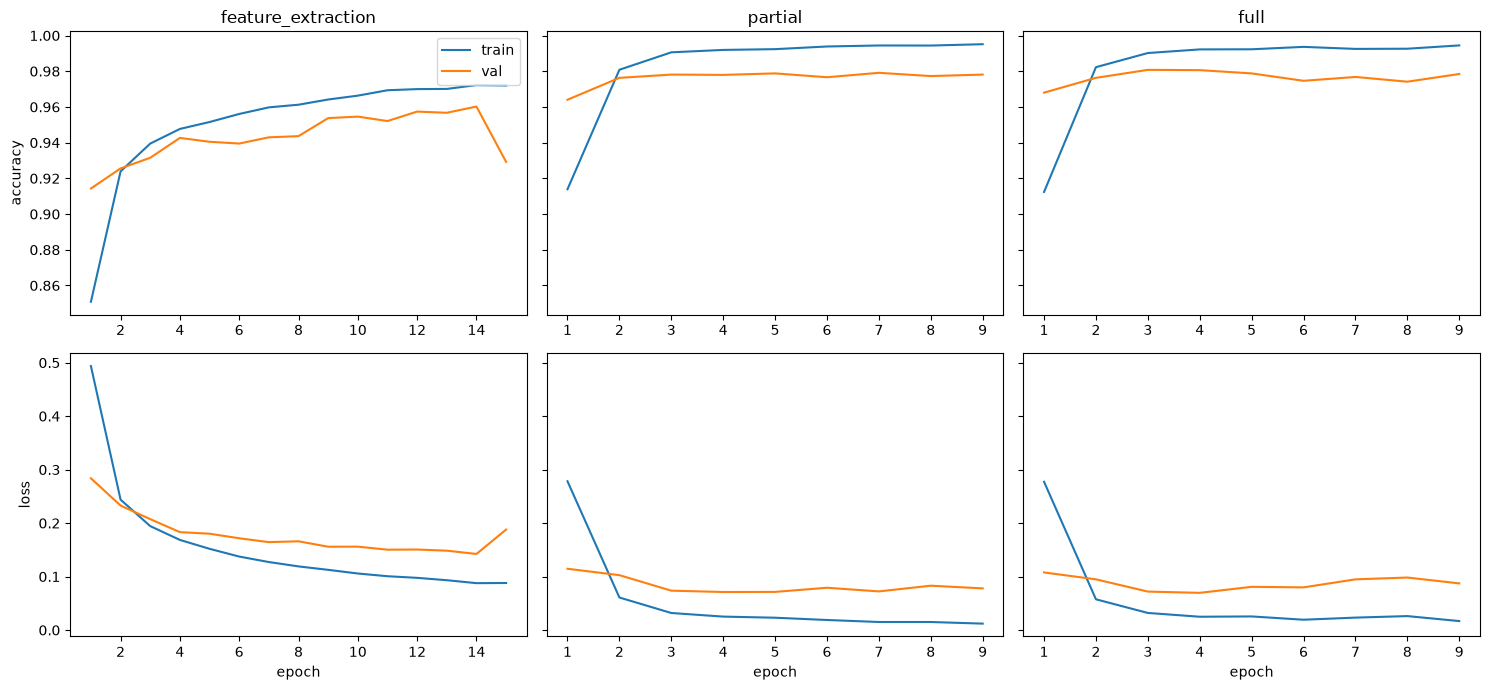

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey="row")
for j, s in enumerate(STRATEGIES):
    
    h = pd.read_csv(PROJECT_ROOT / "results" / f"{RUN_PREFIX}_{s}" / "history.csv")
    axes[0, j].plot(h.epoch, h.train_acc, label="train"); axes[0, j].plot(h.epoch, h.val_acc, label="val")
    axes[1, j].plot(h.epoch, h.train_loss, label="train"); axes[1, j].plot(h.epoch, h.val_loss, label="val")
    axes[0, j].set_title(s); axes[1, j].set_xlabel("epoch")
    
axes[0, 0].set_ylabel("accuracy"); axes[1, 0].set_ylabel("loss"); axes[0, 0].legend()
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "figures" / f"{RUN_PREFIX}_curves.png", dpi=150)
plt.show()

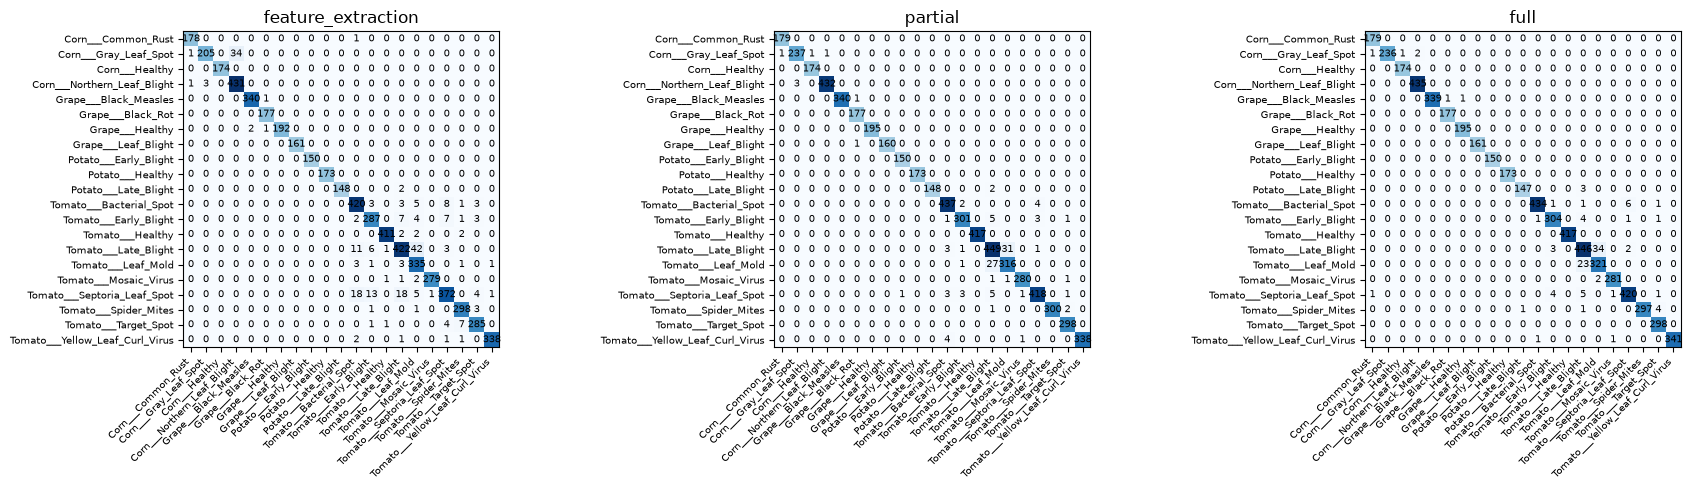

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, s in zip(axes, STRATEGIES):
    
    d = np.load(PROJECT_ROOT / "results" / f"{RUN_PREFIX}_{s}" / "preds.npz")
    cm = confusion_matrix(d["y_true"], d["y_prob"].argmax(1))
    
    ax.imshow(cm, cmap="Blues"); ax.set_title(s)
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASSES, rotation=45, ha="right", fontsize=7)
    ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASSES, fontsize=7)
    
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", fontsize=7)
        
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "figures" / f"{RUN_PREFIX}_confusion.png", dpi=150)
plt.show()